In [3]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print(duckdb.sql("SELECT 'setup works!' AS message").df())

        message
0  setup works!


## 1. Load and prepare the data

In [4]:
# Load orders and keep only the purchase date
orders = pd.read_csv("data/olist_orders_dataset.csv",
                     parse_dates=["order_purchase_timestamp"])

# Count orders per day
daily = (orders
         .groupby(orders["order_purchase_timestamp"].dt.date)
         .size()
         .rename("txn_volume"))
daily.index = pd.to_datetime(daily.index)

# Keep the reliable period (the shop was launching before Feb 2017,
# and data collection stops in late Aug 2018)
daily = daily["2017-02-01":"2018-08-21"]

# Make sure every day exists (fill any missing day with 0 orders)
full_range = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(full_range, fill_value=0)

df = daily.rename_axis("date").reset_index()
df["day_of_month"] = df["date"].dt.day

print(df.shape)
df.head()

(567, 3)


,date,txn_volume,day_of_month
0,2017-02-01,73,1
1,2017-02-02,69,2
2,2017-02-03,60,3
3,2017-02-04,67,4
4,2017-02-05,75,5


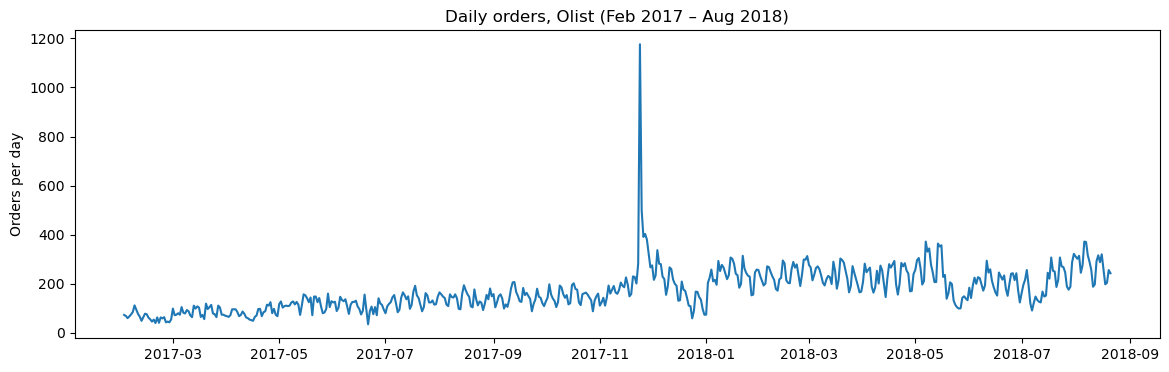

In [5]:
plt.figure(figsize=(14, 4))
plt.plot(df["date"], df["txn_volume"])
plt.title("Daily orders, Olist (Feb 2017 – Aug 2018)")
plt.ylabel("Orders per day")
plt.show()

## 2. Seasonal detector (same day-of-month)

In [6]:
query = open("sql/seasonal_detector.sql").read()
results = duckdb.sql(query).df()   # DuckDB reads the `df` DataFrame directly

print(results["status"].value_counts())
results[results["status"].isin(["WARNING", "CRITICAL"])]

status
NORMAL                342
NOT_ENOUGH_HISTORY    124
WARNING                57
CRITICAL               44
Name: count, dtype: int64


,date,day_of_month,txn_volume,baseline_mean,baseline_std,n_history,z_score,status
124,2017-06-05,5,147,89.000,17.832555,4,3.252478,CRITICAL
125,2017-06-06,6,134,98.750,10.657548,4,3.307515,CRITICAL
132,2017-06-13,13,126,80.500,21.702534,4,2.096529,WARNING
146,2017-06-27,27,141,79.250,27.909079,4,2.212542,WARNING
152,2017-07-03,3,118,79.600,16.652327,5,2.305984,WARNING
...,...,...,...,...,...,...,...,...
532,2018-07-18,18,307,222.250,38.625491,8,2.194147,WARNING
545,2018-07-31,31,322,152.125,50.898884,8,3.337499,CRITICAL
548,2018-08-03,3,314,228.250,36.244211,8,2.365895,WARNING
551,2018-08-06,6,372,222.875,52.572229,8,2.836574,WARNING
